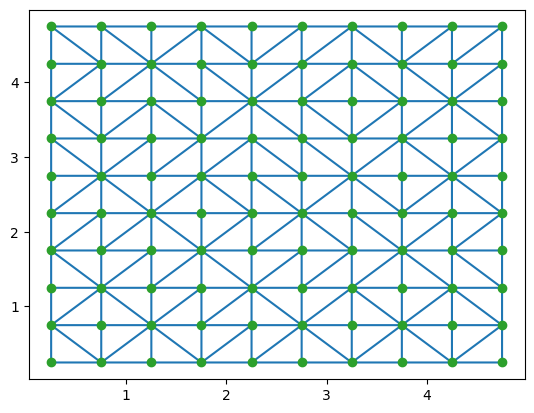

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import clear_output

grav = 9.8
Nx, Ny, L = 10, 10, 5.0
dx = L / Nx
dy = L / Ny
x = (np.arange(Nx) + 0.5) * dx
y = (np.arange(Ny) + 0.5) * dy
X, Y = np.meshgrid(x, y)

points = np.array([X.flatten(), Y.flatten()]).T

from scipy.spatial import Delaunay
mesh = Delaunay(points)

plt.triplot(points[:,0], points[:,1], mesh.simplices)
plt.plot(points[:,0], points[:,1], 'o')
plt.show()

In [2]:
# COMPUTE EDGES INFORMATION
elems = mesh.simplices
edges_info = {}

for elem_idx, elem in enumerate(elems):
    # COMPUTE ELEMENT POINT INDICES
    elem = elem.astype(int)
    edges_idx = [ (elem[0], elem[1]),  (elem[1], elem[2]),  (elem[2], elem[0]) ]
    
    for idx1, idx2 in edges_idx:
        # ORDER INDICES 
        edge_ID = (min(idx1, idx2), max(idx1, idx2))

        if edge_ID not in edges_info:
            # EDGE POINTS
            p1, p2 = points[edge_ID[0]], points[edge_ID[1]]
            
            # EDGE LENGTH
            diff_vec = p2 - p1
            edge_length = np.linalg.norm(diff_vec)
    
            # EDGE NORMAL VECTOR
            nx = -diff_vec[1] / edge_length
            ny = diff_vec[0] / edge_length
            
            edges_info[edge_ID] = {
                'idxs': edge_ID,
                'length': edge_length,
                'normal': (nx, ny),
                'elemL': elem_idx,
                'elemR': -1,
                'boundary': True
            }
        else:
            edges_info[edge_ID]['elemR'] = elem_idx
            edges_info[edge_ID]['boundary'] = False

print(f"EDGE INFO COMPUTING SUCCESSFULL!")

EDGE INFO COMPUTING SUCCESSFULL!


In [3]:
# COMPUTE ELEMENTS INFORMATION
elems_info = {}

for elem_idx, elem in enumerate(elems):
    # COMPUTE ELEMENT POINT INDICES
    elem = elem.astype(int)
    idx1, idx2, idx3 = elem[0], elem[1], elem[2]
    p1, p2, p3 = points[idx1], points[idx2], points[idx3]

    center = (p1 + p2 + p3) / 3.0
    area = 0.5 * abs(p1[0]*(p2[1] - p3[1]) + p2[0]*(p3[1] - p1[1]) + p3[0]*(p1[1] - p2[1]))

    edges_ID = [ 
        (min(idx1, idx2), max(idx1, idx2)), 
        (min(idx2, idx3), max(idx2, idx3)), 
        (min(idx3, idx1), max(idx3, idx1))
    ]
    
    elems_info[elem_idx] = {
        'vert_idx': (idx1, idx2, idx3),
        'edges_ID': edges_ID,
        'center': center,
        'area': area
    }

print(f"ELEMENTS INFO COMPUTING SUCCESSFULL!")

ELEMENTS INFO COMPUTING SUCCESSFULL!


In [4]:
N = len(elems_info)

Q = np.zeros((3, N))

xhat, yhat = 2.0, 2.0

for elem_idx in range(N):
    xc, yc = elems_info[elem_idx]['center']
    h0 = 1.0 + 0.3 * np.exp(-50.0 * ((xc - xhat)**2 + (yc - yhat)**2))
    Q[0, elem_idx] = h0
    Q[1, elem_idx], Q[2, elem_idx] = 0.0, 0.0

print("PERFECT INITIAL CONDITION!")

PERFECT INITIAL CONDITION!


In [6]:
Qp = Q.copy()
Qn = Qp.copy()

dQ_dt = np.zeros_like(Q)

for edge_key, edge_info in edges_info.items():
    elemL_key = edge_info['elemL']
    qL = Q[:, elemL_key]
    hL, huL, hvL = qL
    uL, vL = huL / hL, hvL / hL

    nx, ny = edge_info['normal']
    
    if edge_info['boundary'] == True:
        # Ghost states
        hR = hL
        
        unL = uL * nx + vL * ny
        utL = -uL * ny + vL * nx
        
        unR = -unL
        utR = utL

        uR = unR * nx - utR * ny
        vR = unR * ny + utR * nx
        
        huR, hvR = hR * uR, hR * vR
        qR = np.array([hR, huR, hvR])
    else:
        edgeR_key = edge_info['elemR'] 
        qR = Q[:, edgeR_key]
        hR, huR, hvR = qR
        uR, vR = huR / hR, hvR / hR

    unL = uL * nx + vL * ny
    unR = uR * nx + vR * ny

    F1L = hL * unL
    F2L = hL * unL * uL + 0.5 * grav * hL**2 * nx
    F3L = hL * unL * vL + 0.5 * grav * hL**2 * ny

    F1R = hR * unR
    F2R = hR * unR * uR + 0.5 * grav * hR**2 * nx
    F3R = hR * unR * vR + 0.5 * grav * hR**2 * ny

    velL = np.abs(unL) + np.sqrt(grav * hL)
    velR = np.abs(unR) + np.sqrt(grav * hR)
    a = max(velL, velR)
    
    flux1 = 0.5 * (F1L + F1R) - 0.5 * a * (hR - hL)
    flux2 = 0.5 * (F2L + F2R) - 0.5 * a * (huR - huL)
    flux3 = 0.5 * (F3L + F3R) - 0.5 * a * (hvR - hvL)

    F_num = np.array([flux1, flux2, flux3])
    
    edge_length = edge_info['length']
    areaL = elems_info[elemL_key]['area']
    dQ_dt[:, elemL_key] -= (F_num * edge_length) / areaL
    
    if not edge_info['boundary']: 
        elemR_idx = edge_info['elemR']
        areaR = elems_info[elemR_idx]['area']
        dQ_dt[:, elemR_idx] += (F_num * edge_length) / areaR
        
    break

# TODAVIA POR TERMINAR ESTO

In [ ]:
for edge_key, info in edges_info.items():
    print(edge_key, edge)
    break